# Pergunta 1 — Incidência e mortalidade do câncer de mama por região e UF

**Pergunta:** como variam a incidência e a mortalidade entre regiões e UFs?

**Base utilizada:** `base_uf.csv` (base tratada), com 27 UFs. Fontes: INCA (incidência e mortalidade).



## 1. Importação e carregamento dos dados

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO

dados = """
uf_sigla,uf_nome,regiao,incid_casos,incid_taxa_bruta,incid_taxa_ajustada,mort_obitos_2023,mort_taxa_bruta_2023,mort_taxa_ajustada_2023,pop_feminina_estimada
AC,Acre,Norte,100,22.21,26.2,31,07.09,7.17,450248
AM,Amazonas,Norte,500,22.77,28.34,253,12.0,12.25,2195872
AP,Amapá,Norte,80,16.58,20.04,26,6.51,7.12,482509
PA,Pará,Norte,1020,22.83,23.88,382,8.91,08.09,4467806
RO,Rondônia,Norte,320,35.33,36.99,118,13.65,11.53,905746
RR,Roraima,Norte,70,22.09,27.73,51,14.89,17.38,316885
TO,Tocantins,Norte,320,38.58,35.72,74,9.51,7.97,829445
AL,Alagoas,Nordeste,690,39.23,34.89,246,14.76,11.59,1758858
BA,Bahia,Nordeste,4230,54.35,43.28,1218,15.99,11.24,7782889
CE,Ceará,Nordeste,3080,63.92,54.13,802,16.96,12.26,4818523
MA,Maranhão,Nordeste,1060,28.76,28.29,304,8.57,7.33,3685675
PB,Paraíba,Nordeste,1180,55.4,41.37,317,14.9,10.27,2129964
PE,Pernambuco,Nordeste,2880,56.58,46.4,876,17.72,12.41,5090138
PI,Piauí,Nordeste,860,50.31,41.89,219,12.74,9.12,1709402
RN,Rio Grande do Norte,Nordeste,1140,61.61,50.11,346,19.63,13.62,1850349
SE,Sergipe,Nordeste,570,46.42,42.11,189,15.97,11.78,1227919
ES,Espírito Santo,Sudeste,900,42.2,32.94,378,18.18,12.08,2132701
MG,Minas Gerais,Sudeste,7670,69.8,49.28,1829,16.9,10.59,10988539
RJ,Rio de Janeiro,Sudeste,10290,111.83,70.57,2506,27.75,16.5,9201467
SP,São Paulo,Sudeste,20470,84.43,56.37,4993,21.12,13.29,24244937
PR,Paraná,Sul,3650,60.76,41.06,1240,20.64,13.53,6007242
RS,Rio Grande do Sul,Sul,3720,62.67,36.6,1536,26.6,14.89,5935854
SC,Santa Catarina,Sul,3860,102.12,74.79,823,20.55,13.68,3779867
DF,Distrito Federal,Centro-Oeste,1030,62.7,49.76,253,16.33,12.03,1642743
GO,Goiás,Centro-Oeste,1970,52.74,45.63,635,17.25,12.74,3735305
MS,Mato Grosso do Sul,Centro-Oeste,910,62.22,47.1,265,18.25,13.61,1462552
MT,Mato Grosso,Centro-Oeste,1040,57.7,47.51,255,13.61,11.42,1802426
"""

df = pd.read_csv(StringIO(dados.strip()))
df.head()

,uf_sigla,uf_nome,regiao,incid_casos,incid_taxa_bruta,incid_taxa_ajustada,mort_obitos_2023,mort_taxa_bruta_2023,mort_taxa_ajustada_2023,pop_feminina_estimada
0,AC,Acre,Norte,100,22.21,26.20,31,7.09,7.17,450248
1,AM,Amazonas,Norte,500,22.77,28.34,253,12.00,12.25,2195872
2,AP,Amapá,Norte,80,16.58,20.04,26,6.51,7.12,482509
3,PA,Pará,Norte,1020,22.83,23.88,382,8.91,8.09,4467806
4,RO,Rondônia,Norte,320,35.33,36.99,118,13.65,11.53,905746


## 2. Seleção e checagem das colunas

Para esta pergunta usamos apenas as colunas de identificação, incidência, mortalidade e população feminina.
Convertemos tudo para número com `pd.to_numeric`, porque algumas células da planilha podem ter sido lidas como texto (ex.: `07.09`).

In [ ]:
colunas_texto = ["uf_sigla", "uf_nome", "regiao"]
colunas_num = ["incid_casos", "incid_taxa_bruta", "incid_taxa_ajustada",
               "mort_obitos_2023", "mort_taxa_bruta_2023", "mort_taxa_ajustada_2023",
               "pop_feminina_estimada"]

d = df[colunas_texto + colunas_num].copy()
for c in colunas_num:
    d[c] = pd.to_numeric(d[c], errors="coerce")

print("Linhas (UFs):", len(d))
print("\nValores nulos por coluna:")
print(d.isna().sum())
d.describe().round(2)

Linhas (UFs): 27

Valores nulos por coluna:
uf_sigla                   0
uf_nome                    0
regiao                     0
incid_casos                0
incid_taxa_bruta           0
incid_taxa_ajustada        0
mort_obitos_2023           0
mort_taxa_bruta_2023       0
mort_taxa_ajustada_2023    0
pop_feminina_estimada      0
dtype: int64


,incid_casos,incid_taxa_bruta,incid_taxa_ajustada,mort_obitos_2023,mort_taxa_bruta_2023,mort_taxa_ajustada_2023,pop_feminina_estimada
count,27.00,27.00,27.00,27.00,27.00,27.00,27.00
mean,2726.30,52.08,41.96,746.85,15.81,11.68,4097624.48
std,4275.69,23.38,12.98,1045.12,5.21,2.65,4874109.06
min,70.00,16.58,20.04,26.00,6.51,7.12,316885.00
25%,630.00,36.96,33.92,232.50,13.18,10.43,1552647.50
50%,1040.00,54.35,41.89,317.00,15.99,12.03,2132701.00
75%,3365.00,62.44,48.40,849.50,18.22,13.41,4954330.50
max,20470.00,111.83,74.79,4993.00,27.75,17.38,24244937.00


**Observação sobre a qualidade dos dados:** a coluna `razao_mortalidade_incidencia` da planilha mistura escalas (valores como `274` e `0.26` na mesma coluna).
Por isso, **recalculamos a razão** a partir das colunas originais: óbitos (2023) ÷ casos de incidência.

Além disso, usamos as **taxas ajustadas por idade** para comparar UFs. As taxas brutas dependem da estrutura etária de cada população
(estados com população mais velha tendem a ter taxa bruta maior), então a ajustada é mais justa para comparar.

In [ ]:
d["razao_mort_incid"] = (d["mort_obitos_2023"] / d["incid_casos"]).round(3)
d[["uf_sigla", "incid_casos", "mort_obitos_2023", "razao_mort_incid"]].head()

,uf_sigla,incid_casos,mort_obitos_2023,razao_mort_incid
0,AC,100,31,0.310
1,AM,500,253,0.506
2,AP,80,26,0.325
3,PA,1020,382,0.375
4,RO,320,118,0.369


## 3. Comparação entre regiões

Para a taxa **bruta** regional, somamos casos (ou óbitos) e dividimos pela população feminina somada da região (média ponderada, sem dar o mesmo peso a UFs de tamanhos muito diferentes).
Para a taxa **ajustada**, usamos a média simples das UFs, porque não temos como reponderar a padronização por idade apenas com esta base.

In [ ]:
reg = d.groupby("regiao").agg(
    casos=("incid_casos", "sum"),
    obitos=("mort_obitos_2023", "sum"),
    pop=("pop_feminina_estimada", "sum"),
    incid_ajust_media=("incid_taxa_ajustada", "mean"),
    incid_ajust_min=("incid_taxa_ajustada", "min"),
    incid_ajust_max=("incid_taxa_ajustada", "max"),
    mort_ajust_media=("mort_taxa_ajustada_2023", "mean"),
    mort_ajust_min=("mort_taxa_ajustada_2023", "min"),
    mort_ajust_max=("mort_taxa_ajustada_2023", "max"),
)
reg["incid_bruta_100mil"] = reg["casos"] / reg["pop"] * 1e5
reg["mort_bruta_100mil"] = reg["obitos"] / reg["pop"] * 1e5
reg["razao_mort_incid"] = reg["obitos"] / reg["casos"]

reg = reg.drop(columns=["pop"]).round(2).sort_values("incid_ajust_media", ascending=False)
reg

,casos,obitos,incid_ajust_media,incid_ajust_min,incid_ajust_max,mort_ajust_media,mort_ajust_min,mort_ajust_max,incid_bruta_100mil,mort_bruta_100mil,razao_mort_incid
regiao,,,,,,,,,,,
Sudeste,39330,9706,52.29,32.94,70.57,13.12,10.59,16.50,84.46,20.84,0.25
Sul,11230,3599,50.82,36.60,74.79,14.03,13.53,14.89,71.42,22.89,0.32
Centro-Oeste,4950,1408,47.50,45.63,49.76,12.45,11.42,13.61,57.27,16.29,0.28
Nordeste,15690,4517,42.50,28.29,54.13,11.07,7.33,13.62,52.21,15.03,0.29
Norte,2410,935,28.41,20.04,36.99,10.22,7.12,17.38,24.98,9.69,0.39


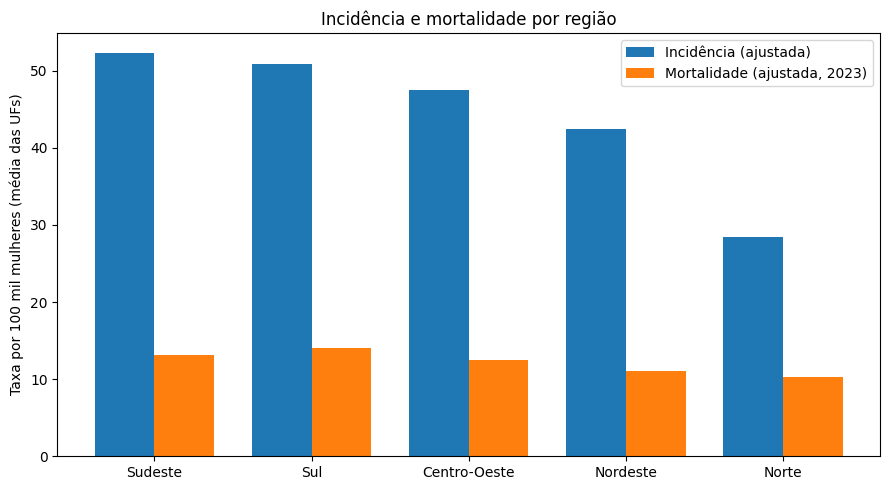

In [ ]:
ordem = reg.index.tolist()
x = range(len(ordem))
larg = 0.38

plt.figure(figsize=(9, 5))
plt.bar([i - larg/2 for i in x], reg["incid_ajust_media"], width=larg, label="Incidência (ajustada)")
plt.bar([i + larg/2 for i in x], reg["mort_ajust_media"], width=larg, label="Mortalidade (ajustada, 2023)")
plt.xticks(list(x), ordem)
plt.ylabel("Taxa por 100 mil mulheres (média das UFs)")
plt.title("Incidência e mortalidade por região")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretação

O Sudeste tem a maior incidência média (cerca de 52 por 100 mil mulheres) e o Norte a menor (cerca de 28). A ordem das regiões na mortalidade não é a mesma da incidência.


## 4. Comparação entre UFs

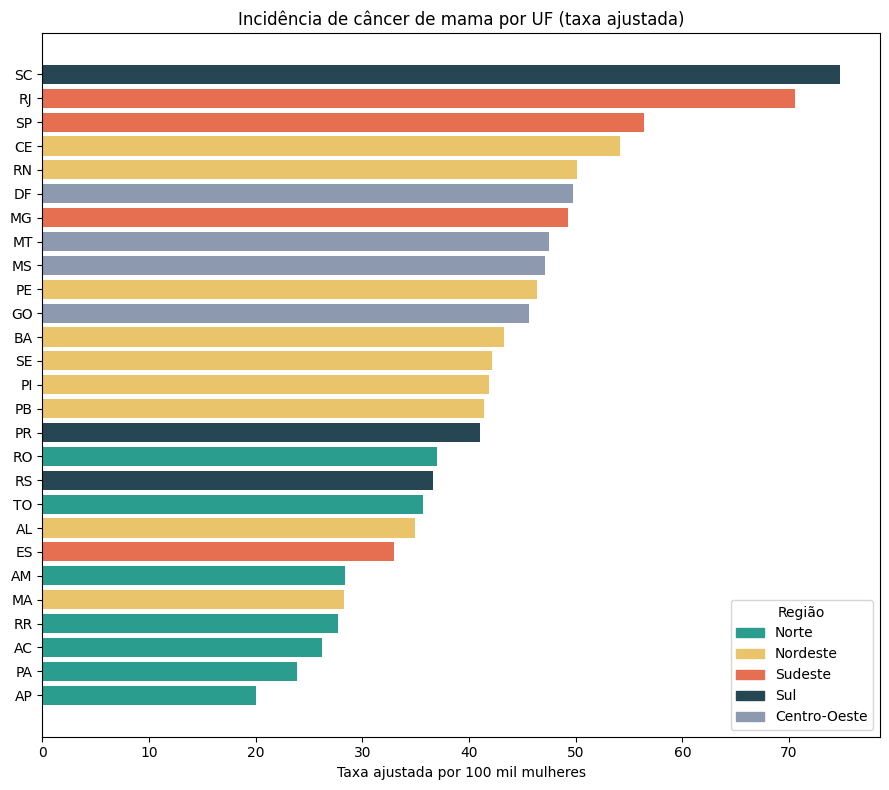

,uf_sigla,regiao,incid_taxa_ajustada
22,SC,Sul,74.79
18,RJ,Sudeste,70.57
19,SP,Sudeste,56.37
9,CE,Nordeste,54.13
14,RN,Nordeste,50.11


In [ ]:
cores = {"Norte": "#2a9d8f", "Nordeste": "#e9c46a", "Sudeste": "#e76f51",
         "Sul": "#264653", "Centro-Oeste": "#8d99ae"}

def ranking(coluna, titulo, xlabel):
    r = d.sort_values(coluna, ascending=False)
    plt.figure(figsize=(9, 8))
    plt.barh(r["uf_sigla"], r[coluna], color=r["regiao"].map(cores))
    plt.gca().invert_yaxis()
    plt.xlabel(xlabel)
    plt.title(titulo)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in cores.values()]
    plt.legend(handles, cores.keys(), title="Região", loc="lower right")
    plt.tight_layout()
    plt.show()
    return r

r_incid = ranking("incid_taxa_ajustada",
                  "Incidência de câncer de mama por UF (taxa ajustada)",
                  "Taxa ajustada por 100 mil mulheres")
r_incid[["uf_sigla", "regiao", "incid_taxa_ajustada"]].head(5)

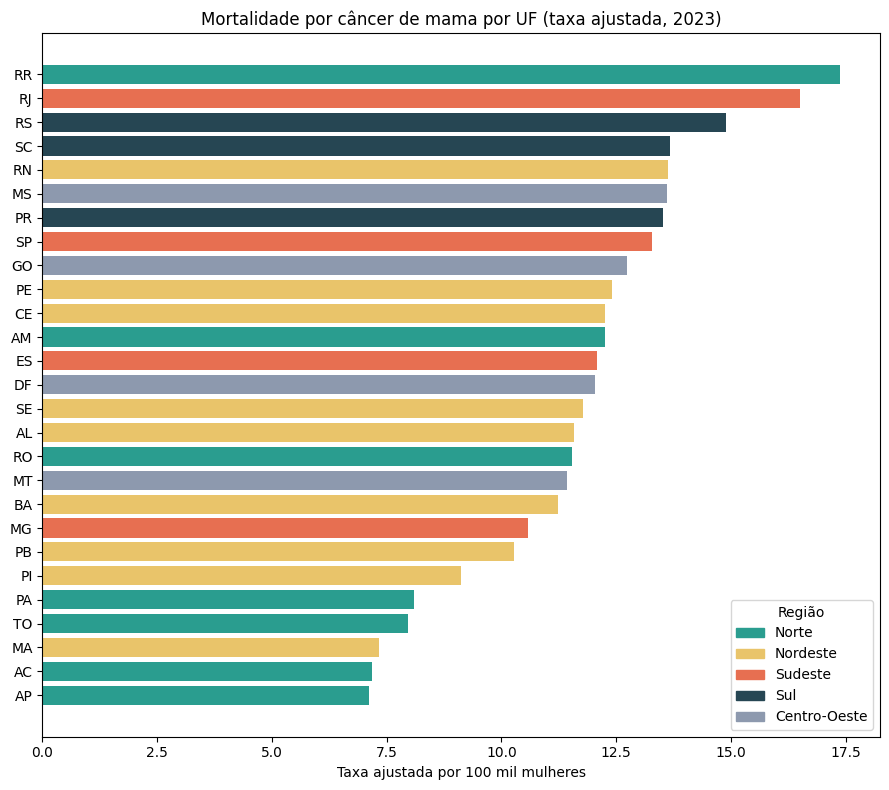

,uf_sigla,regiao,mort_taxa_ajustada_2023
5,RR,Norte,17.38
18,RJ,Sudeste,16.50
21,RS,Sul,14.89
22,SC,Sul,13.68
14,RN,Nordeste,13.62


In [ ]:
r_mort = ranking("mort_taxa_ajustada_2023",
                 "Mortalidade por câncer de mama por UF (taxa ajustada, 2023)",
                 "Taxa ajustada por 100 mil mulheres")
r_mort[["uf_sigla", "regiao", "mort_taxa_ajustada_2023"]].head(5)

**Interpretação

A incidência ajustada é mais alta em Santa Catarina e no Rio de Janeiro, seguidos de São Paulo e Ceará. Os menores valores estão no Amapá, no Pará e no Acre, todos da região Norte. A mortalidade ajustada não repete exatamente a mesma ordem: o Rio de Janeiro continua entre os primeiros, mas Roraima tem a maior taxa do país mesmo com incidência baixa, e o Rio Grande do Sul aparece em terceiro apesar de uma incidência intermediária. As menores mortalidades estão no Amapá, no Acre e no Maranhão. Ou seja, UFs com incidência semelhante podem ter mortalidades bem diferentes.

## 5. Relação entre incidência e mortalidade

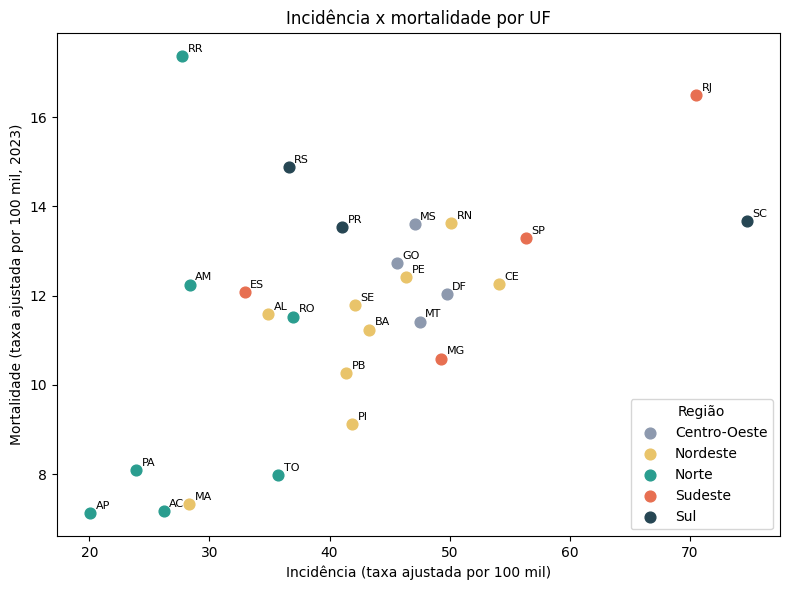

Correlação incidência x mortalidade (ajustadas): 0.52


In [ ]:
plt.figure(figsize=(8, 6))
for regiao, g in d.groupby("regiao"):
    plt.scatter(g["incid_taxa_ajustada"], g["mort_taxa_ajustada_2023"],
                color=cores[regiao], label=regiao, s=60)
for _, row in d.iterrows():
    plt.annotate(row["uf_sigla"], (row["incid_taxa_ajustada"], row["mort_taxa_ajustada_2023"]),
                 xytext=(4, 3), textcoords="offset points", fontsize=8)
plt.xlabel("Incidência (taxa ajustada por 100 mil)")
plt.ylabel("Mortalidade (taxa ajustada por 100 mil, 2023)")
plt.title("Incidência x mortalidade por UF")
plt.legend(title="Região")
plt.tight_layout()
plt.show()

print("Correlação incidência x mortalidade (ajustadas):",
      round(d["incid_taxa_ajustada"].corr(d["mort_taxa_ajustada_2023"]), 2))

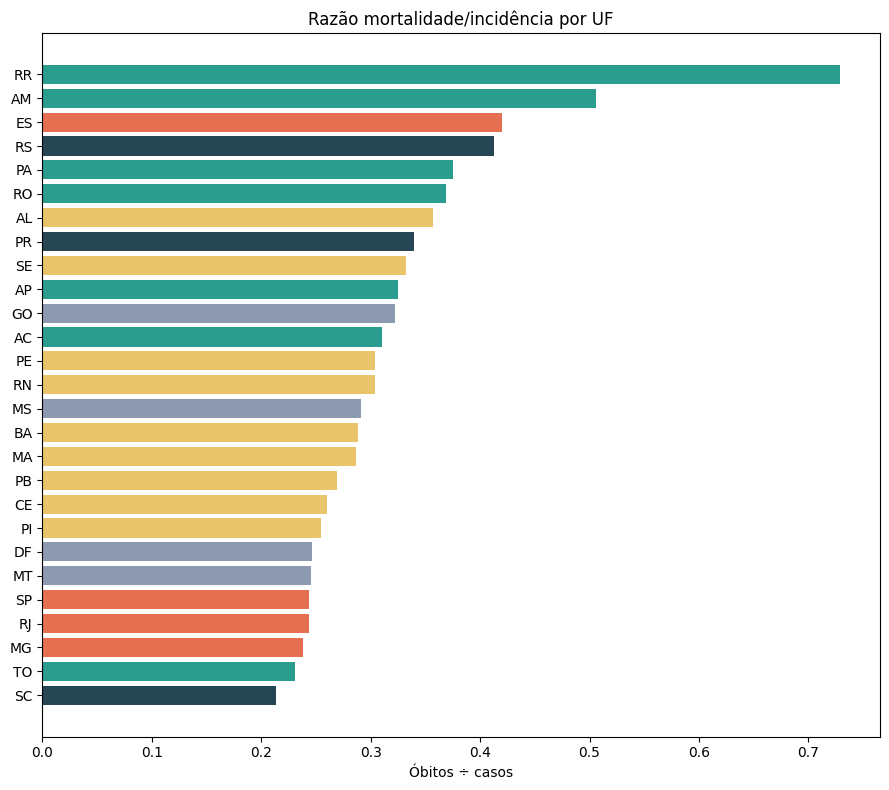

Média da razão por região:
regiao
Norte           0.406
Sul             0.322
Nordeste        0.295
Sudeste         0.286
Centro-Oeste    0.276
Name: razao_mort_incid, dtype: float64


In [ ]:
# Razão mortalidade/incidência: quantos óbitos (2023) para cada caso estimado
r_razao = d.sort_values("razao_mort_incid", ascending=False)
plt.figure(figsize=(9, 8))
plt.barh(r_razao["uf_sigla"], r_razao["razao_mort_incid"], color=r_razao["regiao"].map(cores))
plt.gca().invert_yaxis()
plt.xlabel("Óbitos ÷ casos")
plt.title("Razão mortalidade/incidência por UF")
plt.tight_layout()
plt.show()

print("Média da razão por região:")
print(d.groupby("regiao")["razao_mort_incid"].mean().round(3).sort_values(ascending=False))

**Interpretação

A correlação entre incidência e mortalidade ajustadas é de cerca de 0,5, ou seja, moderada: UFs com mais casos tendem a ter mais óbitos, mas a relação está longe de ser perfeita. Isso aparece no gráfico, onde algumas UFs se afastam do padrão, como Roraima, com mortalidade alta para a incidência que tem. A razão óbitos/casos reforça isso: ela é maior no Norte (cerca de 0,4) do que nas demais regiões (cerca de 0,3), com destaque para Roraima e Amazonas. Isso pode indicar diagnóstico mais tardio ou menor acesso a tratamento nessas UFs, mas é uma hipótese. Também é preciso cautela porque UFs pequenas, como Roraima, têm poucos casos, e pequenas variações mudam muito a taxa.

## 6. Conclusões

A incidência de câncer de mama varia bastante entre as regiões do Brasil. O Sudeste tem a maior taxa ajustada média (cerca de 52 por 100 mil mulheres), seguido de perto pelo Sul (cerca de 51), enquanto o Norte tem a menor (cerca de 28). Entre as UFs, Santa Catarina (74,8) e Rio de Janeiro (70,6) lideram a incidência, e Amapá (20,0) e Pará (23,9) têm os menores valores. A mortalidade segue esse padrão apenas em parte: o Rio de Janeiro e Santa Catarina também estão entre as UFs com maior mortalidade, mas Roraima tem a maior taxa de mortalidade do país (17,4) mesmo com incidência baixa (27,7). A correlação moderada entre incidência e mortalidade (cerca de 0,5) reforça que uma não explica a outra por completo. Além disso, o Norte tem a maior razão óbitos/casos (cerca de 0,4, contra cerca de 0,3 nas demais regiões), o que sugere que a baixa incidência nessa região pode refletir menos diagnóstico, e não menos doença. Essa é uma hipótese que os dados desta análise não permitem confirmar.

## 7. Limitações

- **Anos diferentes:** a incidência é uma estimativa do INCA e a mortalidade é de 2023. Conferir no dicionário de dados o período exato da incidência.
- **Incidência é estimada, não observada:** pode ser menos precisa em UFs pequenas (ex.: AC, AP, RR), onde poucos casos mudam muito a taxa.
- **Subnotificação e diagnóstico:** incidência baixa pode refletir menos diagnóstico, e não menos doença.
- **Razão óbitos/casos é aproximada:** compara óbitos de um ano com casos estimados de outro período, então serve para comparar UFs, não como taxa de letalidade real.
- **Dados agregados por UF:** não permitem concluir nada sobre indivíduos (falácia ecológica).
- **Média simples das taxas ajustadas nas regiões:** não pondera pelo tamanho da população.